# 02 · Clean the data

In notebook 01 we found the raw data has known problems. Here we fix them **one step at a time**, and after each step we check that the fix did what we wanted.

| Step | Problem | Fix |
|---|---|---|
| 1 | Test has different phases | Label every row with its phase |
| 2 | Spikes and glitches | Remove them (carefully) |
| 3 | Injection rate is in barrels/min | Convert to gallons/min, combine the two pressure sensors |
| 4 | Separator flow meters read ~10% high | Fit a calibration line and correct them |
| 5 | Producer thermometer reads ~11 °F low | Add the measured offset |
| 6 | Tiny gaps in the data | Fill short gaps only |
| 7 | Did we break anything? | Validate against the injection rate |
| 8 | Next notebooks need the clean data | Save CSV files |

The golden rule of cleaning: **never overwrite the raw data.** We read from `data/raw/` and write new files to `data/processed/`.

> **Learn:** `df["new_col"] = ...` adds a column without touching the original ones. We use that everywhere, so you can always compare raw vs corrected side by side.

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from load import load_main, load_flow_calibration, load_manual_tp
from clean import (label_phases, remove_bad_values, build_injection_signals,
                   fit_flow_calibration, apply_flow_calibration,
                   temperature_offset, correct_temperature,
                   fill_short_gaps, flag_valid_steady, hampel_flag)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
FIG_DIR = "../figures/"

raw = load_main()
cal = load_flow_calibration()
manual = load_manual_tp()
df = raw.copy()          # we work on a copy; `raw` stays untouched
print(df.shape)

(81239, 10)


## Step 1 · Label the test phases

The test was not one continuous experiment. It had a shut-in period, a stepped ramp-up (2.5 → 5 → 7.5 → 10 bpm), a long steady period at 10 bpm, and a wind-down. We take the start times from the report (Tables 2 and 3) and detect the end of the steady period from the data.

Labelling the phases lets us later say "only look at the steady period" with one line of code.

In [2]:
df["phase"] = label_phases(df)

phases = (df.reset_index()
            .groupby("phase")
            .agg(start=("time", "min"), end=("time", "max"),
                 rows=("time", "size"), median_rate_bpm=("liberty_bpm", "median")))
phases["hours"] = (phases["end"] - phases["start"]).dt.total_seconds().div(3600).round(1)
phases

,start,end,rows,median_rate_bpm,hours
phase,,,,,
0_pre_injection,2024-08-08 07:00:00,2024-08-08 09:29:30,300,NaN,2.5
1_shut_in_2.5bpm,2024-08-08 09:30:00,2024-08-09 16:59:30,3780,2.4780,31.5
2_flow_2.5bpm,2024-08-09 17:00:00,2024-08-10 00:59:30,960,2.4750,8.0
3_step_5bpm,2024-08-10 01:00:00,2024-08-10 12:59:30,1440,5.0050,12.0
4_step_7.5bpm,2024-08-10 13:00:00,2024-08-11 05:59:30,2040,7.5075,17.0
5_steady_10bpm,2024-08-11 06:00:00,2024-09-04 06:00:10,69120,10.0240,576.0
6_wind_down,2024-09-04 06:00:40,2024-09-05 11:59:40,3599,0.0000,30.0


> **Learn:** `groupby("phase")` splits the table into one group per phase. `.agg(...)` then computes one summary per group. This pattern (split → summarise) is the most useful thing in pandas.

**Check:** the median injection rate in each phase matches its name (2.5, 5, 7.5, 10 bpm), so the boundaries from the report line up with the data.

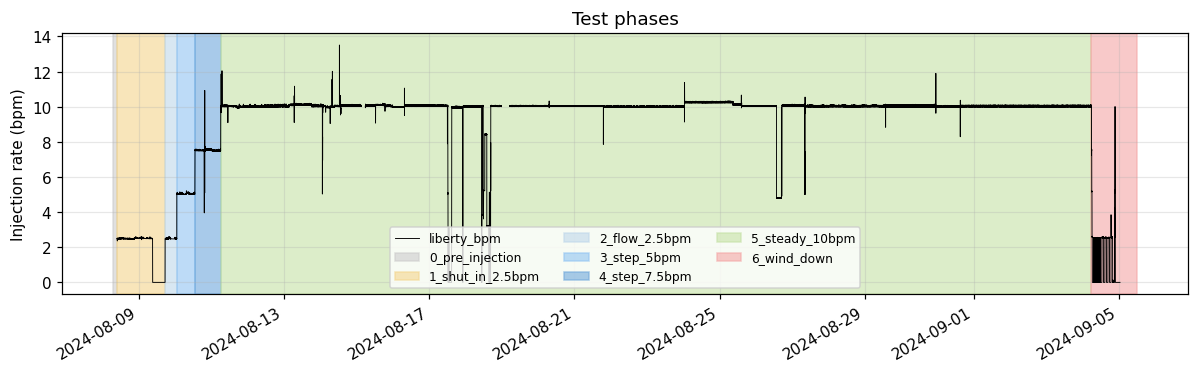

In [3]:
colors = {"0_pre_injection": "#cccccc", "1_shut_in_2.5bpm": "#f4d58d", "2_flow_2.5bpm": "#bfd7ea",
          "3_step_5bpm": "#91c4f2", "4_step_7.5bpm": "#6fa8dc", "5_steady_10bpm": "#c5e1a5", "6_wind_down": "#f4a6a6"}

fig, ax = plt.subplots(figsize=(11, 3.5))
df["liberty_bpm"].plot(ax=ax, color="k", lw=0.6)
for name, row in phases.iterrows():
    ax.axvspan(row["start"], row["end"], color=colors[name], alpha=0.6, label=name)
ax.set_ylabel("Injection rate (bpm)"); ax.set_xlabel("")
ax.set_title("Test phases"); ax.legend(ncol=3, fontsize=8, loc="lower center")
plt.tight_layout(); plt.savefig(FIG_DIR + "02_phases.png"); plt.show()

> **Learn:** `ax.axvspan(x_start, x_end)` shades a vertical band. It is perfect for marking time periods on a plot.

## Step 2 · Remove spikes and impossible values

We saw single-reading spikes (for example the separator flow jumping to 800 gpm for 30 seconds). To find them we use a **Hampel filter**:

1. For each point, take the median of its neighbours (a *rolling median*).
2. If the point is far from that median, it is a spike.

Here is the idea on a tiny made-up example. The lone `95` is a spike, but the real step from `10` up to `25` must survive:

In [4]:
demo = pd.Series([10, 10, 10, 95, 10, 10, 10, 10, 25, 25, 25, 25, 25, 25])
flags = hampel_flag(demo, floor=20)
pd.DataFrame({"value": demo, "is_spike": flags})

,value,is_spike
0,10,False
1,10,False
2,10,False
3,95,True
4,10,False
5,10,False
6,10,False
7,10,False
8,25,False
9,25,False


Only the `95` is flagged. The step to `25` is kept, because after the step the neighbours agree with the new level.

> **Learn:** `s.rolling(7, center=True).median()` gives the median of the 7 readings around each point. Rolling statistics are how you smooth or compare against local behaviour in a time series.

Now apply it to the real data. We also drop values outside physically possible ranges.

In [5]:
clean, counts = remove_bad_values(df)
counts

,valid_before,out_of_range,spikes,valid_after
column,,,,
p16B_psi,80203,0,12,80191
sep1_gpm,73183,3,7,73173
sep2_gpm,71973,1,10,71962
p16A_psi,80876,0,6,80870
liberty_p_psi,77944,0,11,77933
liberty_bpm,78323,0,31,78292
T16B_F,80805,0,6,80799


Very little is removed (between 6 and 31 points out of ~80,000 per column). That is what we want: the cleaning should be **light**.

### A lesson from my first attempt
My first version used a limit of 600 psi on the producer pressure and it removed 3,581 readings, far too many. Before trusting that, I checked *when* those readings happened:

In [6]:
high = df[df["p16B_psi"] > 600]
high.groupby("phase").size().rename("readings above 600 psi")

phase
5_steady_10bpm      89
6_wind_down       3492
Name: readings above 600 psi, dtype: int64

Almost all of them (3,492) are in the **wind-down phase**, where the well was shut in and the pressure really is about 1,400 to 1,600 psi. Those are real, not glitches. We widened the limit so only impossible values are removed.

**Rule:** before deleting extreme values, always ask *when* they happened and *why*. Extreme is not the same as wrong.

Here is what one removed spike looks like (the raw reading is the red cross):

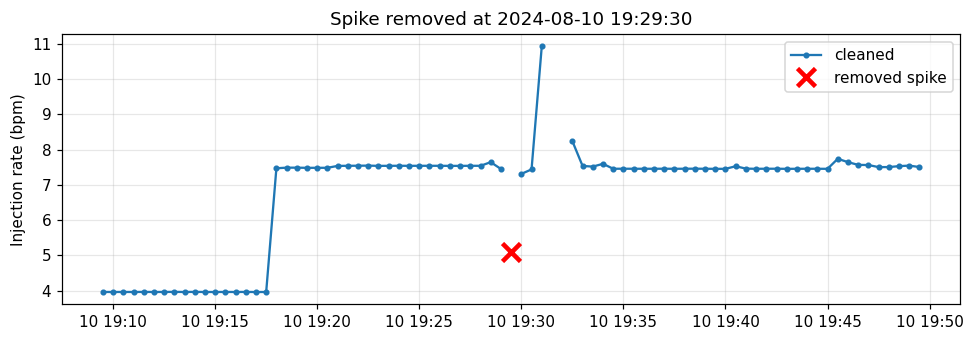

In [7]:
removed = (df["liberty_bpm"].notna() & clean["liberty_bpm"].isna())
t0 = removed[removed].index[0]
win = slice(t0 - pd.Timedelta("20min"), t0 + pd.Timedelta("20min"))

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(clean.loc[win].index, clean.loc[win, "liberty_bpm"], "o-", ms=3, label="cleaned")
ax.plot(df.loc[win].index[df.loc[win, "liberty_bpm"].index == t0], df.loc[t0, "liberty_bpm"], "rx", ms=12, mew=3, label="removed spike")
ax.set_ylabel("Injection rate (bpm)"); ax.set_title(f"Spike removed at {t0}"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR + "02_spike_example.png"); plt.show()

In [8]:
df = clean   # continue with the cleaned table

## Step 3 · Injection signals

Two small jobs:
- Convert the injection rate from barrels per minute to gallons per minute (1 barrel = 42 gallons) so it has the same units as the producer flows.
- We have **two** injection pressure sensors (the 16A transducer and Liberty's). Let's see how well they agree, then build one combined signal.

In [9]:
df = build_injection_signals(df)

diff = (df["p16A_psi"] - df["liberty_p_psi"]).dropna()
steady = df["phase"] == "5_steady_10bpm"
d_steady = diff[steady.reindex(diff.index)]
print("Two pressure sensors, steady phase")
print("  median difference :", round(d_steady.median(), 1), "psi")
print("  middle 90% of diffs:", d_steady.quantile(0.05).round(0), "to", d_steady.quantile(0.95).round(0), "psi")
print("Rows with a combined injection pressure:", df["p_inj_psi"].notna().sum(), "of", len(df))

Two pressure sensors, steady phase
  median difference : -38.5 psi
  middle 90% of diffs: -63.0 to -16.0 psi
Rows with a combined injection pressure: 80902 of 81239


The 16A transducer reads about 38 psi lower than Liberty's sensor (a range of 16 to 63 psi), which is roughly 1.3% of the ~2,900 psi operating pressure. The two follow each other closely, so using the 16A transducer (and falling back to Liberty when it is missing) is reasonable. The small constant difference is worth a line in the README.

## Step 4 · Correct the separator flow meters

This is the most important correction. The calibration file compares each meter with the **pump truck's known rate** (Liberty, our reference). We fit a straight line

$$\text{true flow} = \text{slope} \times \text{meter reading} + \text{intercept}$$

for each meter using `scipy.stats.linregress`.

> **Learn:** `linregress(x, y)` finds the straight line that best fits the points. It returns the slope, the intercept and the correlation. `r_squared` close to 1 means the points sit almost exactly on a line.

In [10]:
fits = fit_flow_calibration(cal)
fits.round(4)

,slope,intercept,r_squared,n_points
meter,,,,
sep1_gpm,0.9074,-9.3102,0.9987,8
sep2_gpm,0.8979,-5.8989,0.9992,8


Both meters have R² > 0.998, so a straight line describes them very well. The slope is about 0.90, which means the meters read roughly **10% high**: a true 100 gpm shows up as about 110 gpm.

Let's see the fit:

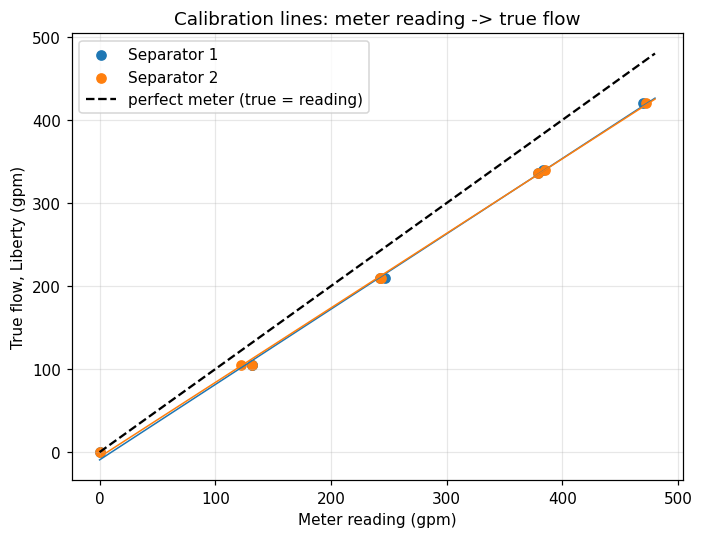

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 5))
x = np.linspace(0, 480, 50)
for col, cal_col, color, label in [("sep1_gpm", "sep1_raw_gpm", "tab:blue", "Separator 1"),
                                   ("sep2_gpm", "sep2_raw_gpm", "tab:orange", "Separator 2")]:
    ax.scatter(cal[cal_col], cal["liberty_gpm"], color=color, label=label)
    # invert the fit only for drawing: reading -> true
    ax.plot(x, fits.loc[col, "slope"] * x + fits.loc[col, "intercept"], color=color, lw=1)
ax.plot(x, x, "k--", label="perfect meter (true = reading)")
ax.set_xlabel("Meter reading (gpm)"); ax.set_ylabel("True flow, Liberty (gpm)")
ax.set_title("Calibration lines: meter reading -> true flow"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR + "02_calibration_fit.png"); plt.show()

The fitted lines sit *below* the dashed line, which is the same thing as saying the meters read high. Now we apply the correction to the full time series.

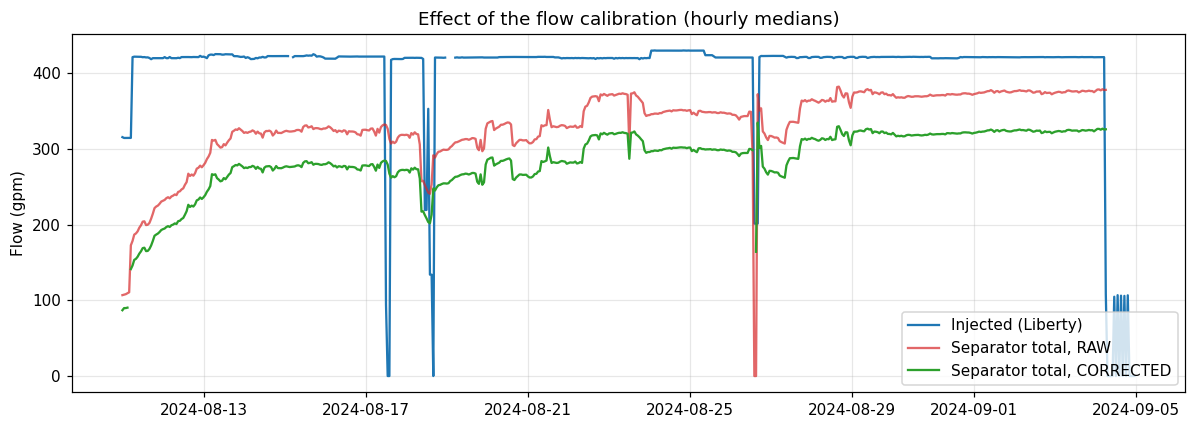

In [12]:
df = apply_flow_calibration(df, fits)

hourly = df.resample("1h").median(numeric_only=True)
st = hourly.loc["2024-08-11":"2024-09-04"]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(st.index, st["inj_gpm"], label="Injected (Liberty)", color="tab:blue")
ax.plot(st.index, st["sep_total_gpm"], label="Separator total, RAW", color="tab:red", alpha=0.7)
ax.plot(st.index, st["sep_total_corr_gpm"], label="Separator total, CORRECTED", color="tab:green")
ax.set_ylabel("Flow (gpm)"); ax.set_title("Effect of the flow calibration (hourly medians)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG_DIR + "02_flow_correction.png"); plt.show()

> **Learn:** `df.resample("1h").median()` groups a time series into hourly blocks and takes the median of each. It turns 120 noisy readings per hour into one robust number, which makes long trends much easier to see.

**Reading this:** the raw separator flow (red) is much closer to the injected rate than it should be. After correction (green) it drops to about 70% of the injected flow. That is expected: the rest leaves the separator **as steam** (the report estimates about 20%), plus some water stays in the rock. We account for the steam in notebook 03.

**Also notice the trend:** the corrected return flow *rises* from about 275 gpm in mid-August to about 325 gpm by September, while injection stays flat near 420 gpm. More of the injected water is coming back as the test goes on. That trend is the main story we quantify in notebook 03.

> **Honest note:** I fitted a straight line with an intercept. The report says it used "regressed equations" but shows them only in a figure, so there may be small differences. The correction only matters at the few-percent level, and we will test how much in notebook 03.

## Step 5 · Correct the producer temperature

The report explains that the thermocouple did not reach all the way into the flowing fluid, so it reads low. Someone also measured the pipe with a temperature gun at about 70 moments during the test. The difference tells us how far off the thermocouple is.

Manual minus Pason: mean = 11.3 °F, standard deviation = 4.6 °F, n = 72 readings


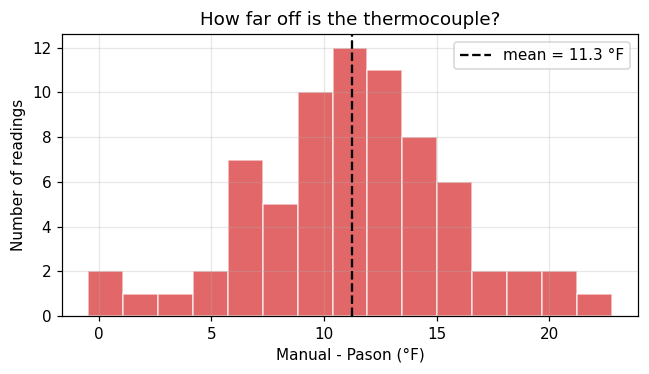

In [13]:
offset, spread, n = temperature_offset(manual)
print(f"Manual minus Pason: mean = {offset:.1f} °F, standard deviation = {spread:.1f} °F, n = {n} readings")

diffs = (manual["T_manual_F"] - manual["T_pason_F"]).dropna()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(diffs, bins=15, color="tab:red", alpha=0.7, edgecolor="white")
ax.axvline(offset, color="k", ls="--", label=f"mean = {offset:.1f} °F")
ax.set_xlabel("Manual - Pason (°F)"); ax.set_ylabel("Number of readings")
ax.set_title("How far off is the thermocouple?"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR + "02_temp_offset_hist.png"); plt.show()

> **Learn:** `ax.hist(values, bins=15)` draws a histogram, which shows how a set of numbers is spread out. It's a quick way to see whether an "average offset" is trustworthy.

The offset is about **+11 °F**, with a spread of about ±4.6 °F. The report says 8–10 °F on average, so we are in the same range (we use all 72 paired readings, so we get a slightly larger number). We add the offset only while hot fluid is flowing, because the problem is a flowing-fluid effect; cold, shut-in readings are left alone.

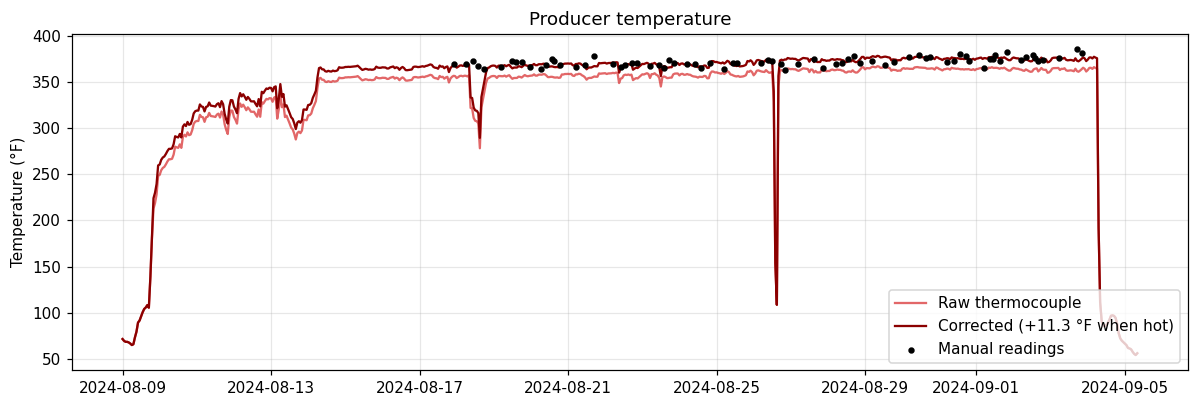

In [14]:
df = correct_temperature(df, offset)

hourly = df.resample("1h").median(numeric_only=True).loc["2024-08-09":"2024-09-05"]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(hourly.index, hourly["T16B_F"], label="Raw thermocouple", color="tab:red", alpha=0.7)
ax.plot(hourly.index, hourly["T16B_corr_F"], label=f"Corrected (+{offset:.1f} °F when hot)", color="darkred")
ax.scatter(manual.index, manual["T_manual_F"], s=10, color="k", label="Manual readings", zorder=3)
ax.set_ylabel("Temperature (°F)"); ax.set_title("Producer temperature"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG_DIR + "02_temperature_correction.png"); plt.show()

The corrected curve passes through the manual readings (black dots), which is the check we wanted.

### What about the producer pressure (`p16B_psi`)?
The manual gauge and the transducer disagree:

In [15]:
dp = (manual["p_manual_psi"] - manual["p_pason_psi"]).dropna()
print(f"Manual gauge minus Pason transducer: mean = {dp.mean():.0f} psi, std = {dp.std():.0f} psi")
print(f"Gauge readings: only {len(dp)} over 4 weeks, versus 80,000 transducer readings")

Manual gauge minus Pason transducer: mean = -55 psi, std = 13 psi
Gauge readings: only 75 over 4 weeks, versus 80,000 transducer readings


The transducer reads about 55 psi higher than the gauge, but the report says the transducer "characteristically read erratically" and was affected by the faulty flow meter, so a constant offset is not justified. **Decision: we keep `p16B_psi` as is, and treat it as indicative only.** The injection pressure (16A) is our trusted pressure signal.

This kind of decision (what *not* to correct, and why) belongs in your README.

## Step 6 · Fill only short gaps

Removing spikes leaves tiny holes. We fill gaps of **at most 10 readings (5 minutes)** with a straight line between the neighbours. Longer gaps stay empty, because inventing 3 hours of flow data would be making things up.

> **Learn:** `s.interpolate(limit=10, limit_area="inside")` fills holes using straight lines. `limit` stops it from bridging long gaps, and `limit_area="inside"` stops it from extending the data past its first or last real reading.

In [16]:
before = df[["sep1_corr_gpm", "sep2_corr_gpm", "T16B_corr_F", "p_inj_psi", "inj_gpm"]].isna().sum()

df = fill_short_gaps(df, ["sep1_corr_gpm", "sep2_corr_gpm", "T16B_corr_F", "p16B_psi", "p_inj_psi", "inj_gpm"])
df["sep_total_corr_gpm"] = df["sep1_corr_gpm"] + df["sep2_corr_gpm"]   # rebuild the sum from filled parts
df["valid_steady"] = flag_valid_steady(df)

after = df[["sep1_corr_gpm", "sep2_corr_gpm", "T16B_corr_F", "p_inj_psi", "inj_gpm"]].isna().sum()
pd.DataFrame({"missing before": before, "missing after": after, "filled": before - after})

,missing before,missing after,filled
sep1_corr_gpm,8066,7971,95
sep2_corr_gpm,9277,8952,325
T16B_corr_F,440,433,7
p_inj_psi,337,332,5
inj_gpm,2947,2840,107


We also created `valid_steady`: **True** only during the steady 10 bpm phase *and* when the pump has been running at full rate for the last 2 hours. This excludes the pump stops (17–18 Aug, 26 Aug) and the settling period after each restart. Notebooks 03 and 04 will use it to compare like with like.

> **A bug I caught while checking.** My first version excluded 2 hours after *any* single reading below 9.5 bpm, and the overview plot showed thin white stripes in the steady period. Investigating showed they came from single 30-second readings dipping to about 9.1 bpm, which are noise, not pump stops. The final rule judges the rate by its 5-minute median, and where the rate record has a gap it accepts an injection pressure above 2,500 psi as evidence that the pump was running. **Lesson: always plot a flag against the data it is meant to describe.**

In [17]:
vs = df["valid_steady"]
print(f"valid_steady rows: {vs.sum():,} of {len(df):,}  ({vs.mean()*100:.0f}% of the whole test, {vs.sum()/120/24:.1f} days)")

core = ["inj_gpm", "p_inj_psi", "sep_total_corr_gpm", "T16B_corr_F", "p16B_psi"]
(df.loc[vs, core].isna().mean() * 100).round(1).rename("% missing inside valid_steady")

valid_steady rows: 65,856 of 81,239  (81% of the whole test, 22.9 days)


inj_gpm               1.8
p_inj_psi             0.0
sep_total_corr_gpm    0.1
T16B_corr_F           0.0
p16B_psi              0.1
Name: % missing inside valid_steady, dtype: float64

## Step 7 · Validate

Cleaning can quietly break things, so we check. First, a set of hard sanity tests. If any fails, Python stops with an error.

In [18]:
assert df.index.is_monotonic_increasing and not df.index.duplicated().any()
assert (df[["sep1_corr_gpm", "sep2_corr_gpm", "sep_total_corr_gpm", "inj_gpm"]].min() >= 0).all()
assert df["T16B_corr_F"].max() < 400
assert df["p_inj_psi"].max() < 3500
assert set(df["phase"].unique()) == set(colors)
assert len(df) == len(raw)          # we never dropped a row
print("All sanity checks passed")

All sanity checks passed


Second, a physical check. In the steady period, how much of the injected water comes back as liquid at the separator?

In [19]:
s = df[df["valid_steady"]]
inj = s["inj_gpm"].median()
sep_raw = s["sep_total_gpm"].median()
sep_cor = s["sep_total_corr_gpm"].median()

print(f"Injected (Liberty)           : {inj:6.1f} gpm")
print(f"Separator total, raw         : {sep_raw:6.1f} gpm  ({sep_raw/inj*100:.0f}% of injected, too high)")
print(f"Separator total, corrected   : {sep_cor:6.1f} gpm  ({sep_cor/inj*100:.0f}% of injected)")
print(f"\nWith the report's ~19.6% steam added back (rough): {sep_cor/(1-0.196)/inj*100:.0f}%   (report: about 90%)")
print(f"Injection pressure: {s['p_inj_psi'].median():.0f} psi   Producer temperature: {s['T16B_corr_F'].median():.0f} °F")

Injected (Liberty)           :  421.1 gpm
Separator total, raw         :  343.1 gpm  (81% of injected, too high)
Separator total, corrected   :  294.6 gpm  (70% of injected)

With the report's ~19.6% steam added back (rough): 87%   (report: about 90%)
Injection pressure: 2867 psi   Producer temperature: 369 °F


Raw, the separator flow looks like 81% of the injection, which would be wrongly optimistic. Corrected, it is about 70% as liquid, and about 87% once the steam is counted. That is close to the report's "approximately 90%" without us tuning anything to match it, which is a good sign that the cleaning is right.

Finally, one overview figure of the cleaned data:

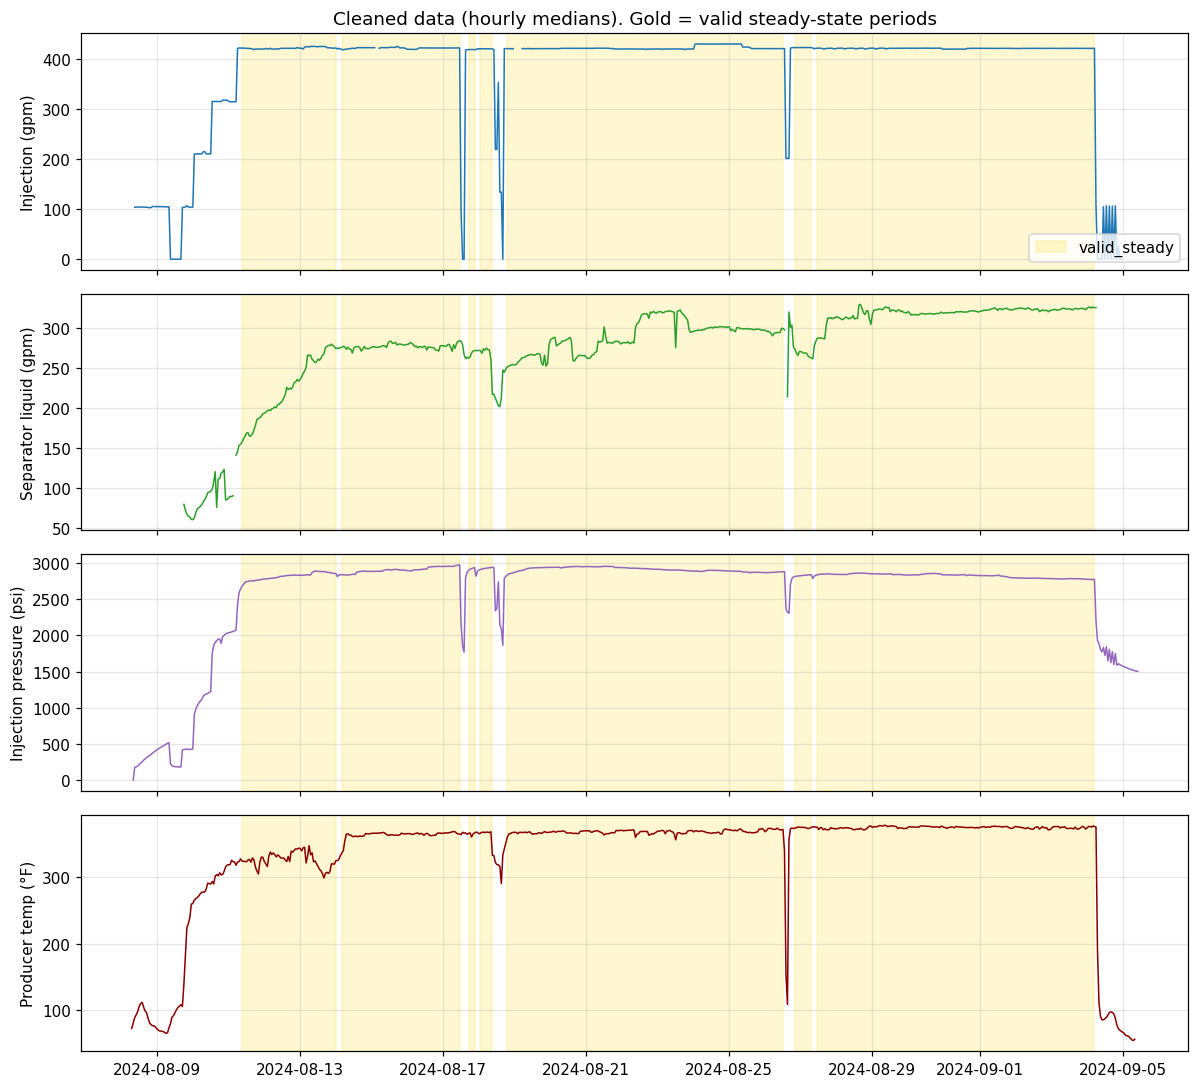

In [20]:
h = df.resample("1h").median(numeric_only=True)
h["valid_steady"] = df["valid_steady"].astype(int).resample("1h").min().astype(bool)

fig, ax = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
panels = [("inj_gpm", "Injection (gpm)", "tab:blue"), ("sep_total_corr_gpm", "Separator liquid (gpm)", "tab:green"),
          ("p_inj_psi", "Injection pressure (psi)", "tab:purple"), ("T16B_corr_F", "Producer temp (°F)", "darkred")]
for a, (col, lab, c) in zip(ax, panels):
    a.plot(h.index, h[col], color=c, lw=1)
    a.fill_between(h.index, 0, 1, where=h["valid_steady"], transform=a.get_xaxis_transform(),
                   color="gold", alpha=0.18, label="valid_steady")
    a.set_ylabel(lab)
ax[0].set_title("Cleaned data (hourly medians). Gold = valid steady-state periods"); ax[0].legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG_DIR + "02_clean_overview.png"); plt.show()

> **Learn:** `sharex=True` makes all the panels share one time axis. `fill_between(..., where=mask)` shades only where a True/False column is True.

**Important:** `valid_steady` means the *injection* is steady. The *production* side is still settling for the first ~3 days of it (second panel: the separator flow and temperature are still climbing until about 14 Aug). So in notebook 03 we will choose the window for the production-side averages more carefully, instead of assuming everything gold is equally steady.

## Step 8 · Save the clean data

We save three small files into `data/processed/`:
- the clean 30-second data (for detailed work),
- an hourly version (fast to plot, good for trends),
- the correction constants (so the README can state exactly what we did).

In [21]:
import os

keep = ["phase", "valid_steady", "inj_gpm", "p_inj_psi",
        "sep1_corr_gpm", "sep2_corr_gpm", "sep_total_corr_gpm",
        "T16B_corr_F", "T16B_F", "p16B_psi", "sep_total_gpm"]
out30 = df[keep]
out30.to_csv("../data/processed/forge_clean_30s.csv", index_label="time")

hourly_out = df[keep].drop(columns=["phase", "valid_steady"]).resample("1h").median()
hourly_out["phase"] = df["phase"].resample("1h").last()
hourly_out["valid_steady"] = df["valid_steady"].astype(int).resample("1h").min().astype(bool)
hourly_out.to_csv("../data/processed/forge_clean_1h.csv", index_label="time")

consts = fits.copy()
consts.loc["T16B_offset_F", ["slope", "intercept"]] = [1.0, offset]
consts["note"] = ["flow: true = slope*reading + intercept"] * 2 + ["temperature: corrected = raw + offset (hot flowing fluid only)"]
consts.to_csv("../data/processed/correction_constants.csv", index_label="name")

for f in sorted(os.listdir("../data/processed")):
    if f.endswith(".csv"):
        print(f"{f:28s} {os.path.getsize('../data/processed/' + f)/1e6:6.2f} MB")

correction_constants.csv       0.00 MB
forge_clean_1h.csv             0.10 MB
forge_clean_30s.csv           11.58 MB


## Summary

| What we did | Result |
|---|---|
| Labelled 7 test phases | Steady 10 bpm phase: 11 Aug to 4 Sep |
| Removed spikes and impossible values | about 90 points in total, out of ~80,000 per column |
| Converted and combined injection signals | `inj_gpm`, `p_inj_psi` |
| Calibrated separator flow meters | meters read ~10% high; corrected with a fitted line (R² > 0.998) |
| Corrected producer temperature | +11 °F while hot fluid flows |
| Left producer pressure alone | transducer unreliable; used as indicative only |
| Filled gaps up to 5 min only | longer gaps remain empty |
| Flagged `valid_steady` | 22.9 days; excludes pump stops and 2 h settling |
| Validated | corrected liquid recovery ~70%, ~87% with steam (report: ~90%) |

**Next:** `03_performance.ipynb`. We will compute injectivity, recovery and the mass-flow efficiency, including the steam correction.